#  Pipeline Técnico: Preprocesamiento de Imágenes + OCR + Limpieza NLP

**Caso de estudio:** Análisis de comunicados institucionales sobre el Fenómeno El Niño 2026-2027 en el Perú.

**Dataset:** 48 documentos (33 relacionados con El Niño / 15 no relacionados) de fuentes oficiales: ENFEN, INDECI, MINSA, SENAMHI, municipalidades.

**Objetivo de esta sección:**
1. Preprocesar las imágenes para mejorar la calidad del OCR.
2. Extraer el texto con EasyOCR (español).
3. Limpiar el texto con técnicas de NLP.
4. Guardar los resultados en `dataset_con_ocr.xlsx` para la siguiente fase (técnicas NLP).

In [1]:
# ============================================================
# Instalación de librerías necesarias
# ============================================================
!pip install -q easyocr opencv-python-headless pymupdf openpyxl

In [2]:
# ============================================================
# aqui subimos el dataset.zip y lo descomprimimos
# Estructura esperada dentro del zip:
#   dataset/
#     ├── nino/        (33 comunicados relacionados con El Niño)
#     └── no_nino/     (15 comunicados no relacionados)
#     └── metadata.xlsx/
# ============================================================
from google.colab import files
import zipfile, os

# 1. Se abre el explorador de archivos: selecciona tu dataset.zip
uploaded = files.upload()

# 2. Descomprimir
with zipfile.ZipFile('dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

# 3. Verificar que las carpetas existen
print("Contenido de dataset/:", os.listdir('dataset'))
print("nino:", len(os.listdir('dataset/nino')), "archivos")
print("no_nino:", len(os.listdir('dataset/no_nino')), "archivos")

Saving dataset.zip to dataset.zip
Contenido de dataset/: ['.Rproj.user', 'no_nino', 'metadata.xlsx', 'nino']
nino: 33 archivos
no_nino: 15 archivos


In [3]:
# ============================================================
# Cargar metadata.xlsx (columnas: carpeta, archivo, institucion, etiqueta, formato)
# y construir la ruta completa de cada documento
# ============================================================
import pandas as pd

metadata = pd.read_excel('dataset/metadata.xlsx')

# Ruta completa: dataset/nino/archivo.png
metadata['ruta'] = 'dataset/' + metadata['carpeta'] + '/' + metadata['archivo']

# Verificar que todos los archivos existen realmente
metadata['existe'] = metadata['ruta'].apply(os.path.exists)
print(metadata['existe'].value_counts())

if not metadata['existe'].all():
    print("\n⚠️ Archivos que no se encontraron:")
    print(metadata.loc[~metadata['existe'], ['carpeta', 'archivo']])

metadata = metadata[metadata['existe']].reset_index(drop=True)
print(f"\n✅ Dataset listo: {len(metadata)} documentos")
metadata.head()

existe
True    48
Name: count, dtype: int64

✅ Dataset listo: 48 documentos


,carpeta,archivo,institucion,etiqueta,formato,ruta,existe
0,no_nino,1430889-comunicado-15-de-agosto.jpeg,Municipalidad de Lima,0,jpeg,dataset/no_nino/1430889-comunicado-15-de-agost...,True
1,no_nino,1431013-com-16-ago-jpg.jpeg,Municipalidad de Lima,0,jpeg,dataset/no_nino/1431013-com-16-ago-jpg.jpeg,True
2,no_nino,1433016-whatsapp-image-2026-08-20-at-10-19-04-...,Municipalidad de Lima,0,jpeg,dataset/no_nino/1433016-whatsapp-image-2026-08...,True
3,no_nino,WhatsApp Image 2026-10-26 at 12.17.32 PM.jpeg,Municipalidad de Comas,0,jpeg,dataset/no_nino/WhatsApp Image 2026-10-26 at 1...,True
4,no_nino,WhatsApp Image 2026-10-26 at 12.18.34 PM.jpeg,Municipalidad de Surco,0,jpeg,dataset/no_nino/WhatsApp Image 2026-10-26 at 1...,True


##  Paso 3: Preprocesamiento de Imágenes

Antes de aplicar OCR, mejoramos la calidad de las imágenes con las siguientes técnicas:

1. **Conversión a escala de grises** → reduce la dimensionalidad y elimina información de color innecesaria.
2. **Eliminación de ruido** (filtro gaussiano) → suaviza manchas y artefactos de compresión (crítico en capturas de Facebook).
3. **Mejora de contraste (CLAHE)** → ecualización adaptativa del histograma; resalta texto sobre fondos difusos o con gradientes.
4. **Binarización adaptativa** → convierte la imagen a blanco/negro calculando el umbral localmente; útil cuando la iluminación no es uniforme.
5. **Redimensionamiento** → si la imagen es muy pequeña, se amplía para que el OCR no pierda caracteres pequeños.

&gt; 💡 **Nota metodológica:** las imágenes que provienen de PDFs nacidos digitales (ENFEN, INDECI) salen casi perfectas; las capturas de redes sociales y fotos de carteles son las que más se benefician del preprocesamiento. Esto se cuantificará en la sección de validación.

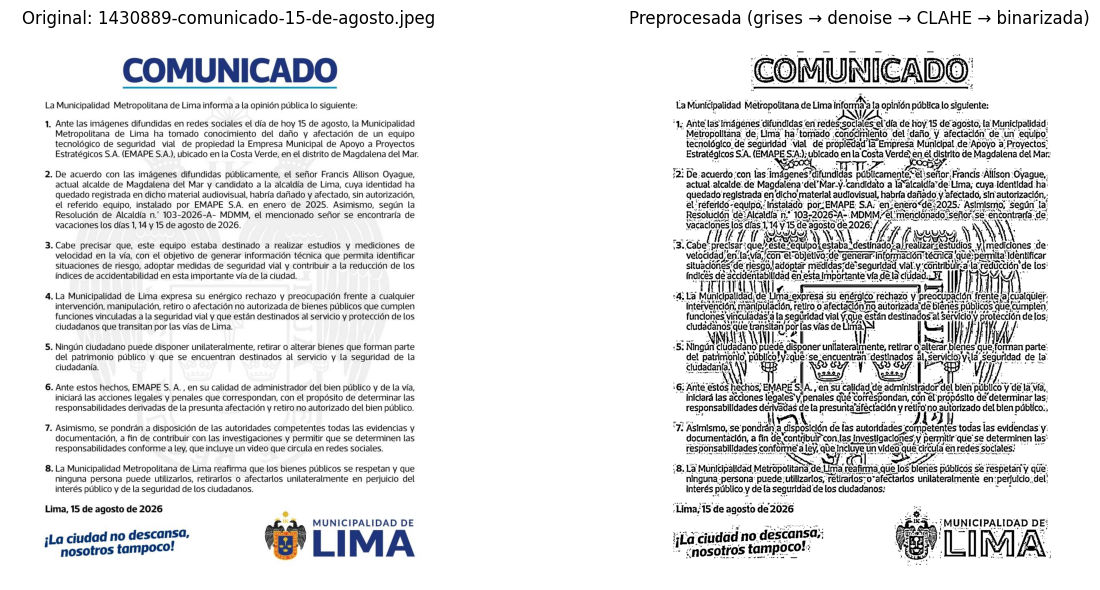

In [4]:
# ============================================================
# Funciones de preprocesamiento de imágenes
# ============================================================
import cv2
import numpy as np

def preprocesar_imagen(ruta, dpi_min=1000):
    """Pipeline de preprocesamiento: grises → denoise → CLAHE → binarización adaptativa."""
    img = cv2.imread(ruta)
    if img is None:
        return None

    # 1. Redimensionar si la imagen es muy pequeña (el OCR pierde letra chica)
    h, w = img.shape[:2]
    if max(h, w) < dpi_min:
        escala = dpi_min / max(h, w)
        img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_CUBIC)

    # 2. Escala de grises
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Eliminación de ruido
    denoise = cv2.GaussianBlur(gris, (3, 3), 0)

    # 4. Mejora de contraste (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    contraste = clahe.apply(denoise)

    # 5. Binarización adaptativa
    binaria = cv2.adaptiveThreshold(contraste, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 11, 2)
    return binaria

# --- PRUEBA VISUAL con un documento ---
import matplotlib.pyplot as plt

ruta_prueba = metadata.loc[0, 'ruta']
original = cv2.imread(ruta_prueba)
procesada = preprocesar_imagen(ruta_prueba)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original: {metadata.loc[0, 'archivo']}")
axes[1].imshow(procesada, cmap='gray')
axes[1].set_title("Preprocesada (grises → denoise → CLAHE → binarizada)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# Paso 4: OCR con EasyOCR (idioma español)
# ============================================================
import easyocr

reader = easyocr.Reader(['es'], gpu=True)  # gpu=True acelera mucho en Colab

# Conversión de PDFs (si quedara alguno sin convertir) a imagen
import fitz  # PyMuPDF

def pdf_a_imagen(ruta, dpi=300):
    doc = fitz.open(ruta)
    pagina = doc[0]  # usamos la primera página
    pix = pagina.get_pixmap(dpi=dpi)
    img_array = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        img_array = cv2.cvtColor(img_array, cv2.COLOR_RGBA2GRAY)
    else:
        img_array = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    return img_array

def ocr_documento(ruta):
    """Aplica preprocesamiento + OCR. Devuelve el texto crudo."""
    if ruta.lower().endswith('.pdf'):
        img = pdf_a_imagen(ruta)
        img_pre = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 11, 2)
    else:
        img_pre = preprocesar_imagen(ruta)
        if img_pre is None:
            return ""

    resultados = reader.readtext(img_pre, detail=0, paragraph=True)
    return " ".join(resultados)

# --- Ejecutar OCR sobre todo el dataset ---
textos_ocr = []
for i, fila in metadata.iterrows():
    try:
        texto = ocr_documento(fila['ruta'])
    except Exception as e:
        texto = f"ERROR: {e}"
    textos_ocr.append(texto)
    print(f"[{i+1}/{len(metadata)}] {fila['archivo'][:40]:40s} → {len(texto)} caracteres")

metadata['texto_ocr'] = textos_ocr
print("\n✅ OCR completado")
metadata[['archivo', 'texto_ocr']].head(3)

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


[1/48] 1430889-comunicado-15-de-agosto.jpeg     → 2440 caracteres
[2/48] 1431013-com-16-ago-jpg.jpeg              → 1677 caracteres
[3/48] 1433016-whatsapp-image-2026-08-20-at-10- → 1310 caracteres
[4/48] WhatsApp Image 2026-10-26 at 12.17.32 PM → 550 caracteres
[5/48] WhatsApp Image 2026-10-26 at 12.18.34 PM → 1243 caracteres
[6/48] WhatsApp Image 2026-10-26 at 12.18.38 PM → 1561 caracteres
[7/48] WhatsApp Image 2026-10-26 at 12.18.59 PM → 1467 caracteres
[8/48] WhatsApp Image 2026-10-26 at 12.21.01 PM → 2495 caracteres
[9/48] WhatsApp Image 2026-10-26 at 12.21.13 PM → 1035 caracteres
[10/48] WhatsApp Image 2026-10-26 at 12.25.47 PM → 866 caracteres
[11/48] WhatsApp Image 2026-10-26 at 12.26.01 PM → 459 caracteres
[12/48] WhatsApp Image 2026-10-26 at 12.26.40 PM → 777 caracteres
[13/48] WhatsApp Image 2026-10-26 at 12.28.51 PM → 735 caracteres
[14/48] WhatsApp Image 2026-10-26 at 12.33.43 PM → 920 caracteres
[15/48] WhatsApp Image 2026-10-26 at 12.33.43 PM → 521 caracteres
[16/48] 022

,archivo,texto_ocr
0,1430889-comunicado-15-de-agosto.jpeg,IMUNICADC (0 LaMunicipalidad Metropolltana deL...
1,1431013-com-16-ago-jpg.jpeg,COMUNICADO La Municipalidad Metropolitana info...
2,1433016-whatsapp-image-2026-08-20-at-10-19-04-...,"MUNICAD@ Respecto a las obras; en 'el; ""IASâp8..."


In [6]:
# ============================================================
# Guardar resultados del OCR en Excel (checkpoint)
# ============================================================
metadata.drop(columns=['existe']).to_excel('dataset_con_ocr.xlsx', index=False)

# Descargar una copia a tu PC (por seguridad)
files.download('dataset_con_ocr.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  Paso 5: Limpieza y Preprocesamiento del Texto

El texto crudo del OCR contiene errores típicos: caracteres especiales mal reconocidos, tildes inconsistentes, espacios dobles y palabras vacías (stopwords) que no aportan significado.

**Técnicas aplicadas:**
1. Conversión a minúsculas.
2. Eliminación de acentos (normaliza variaciones del OCR: "niño" / "nino").
3. Eliminación de caracteres especiales y dígitos sueltos.
4. Corrección de espacios múltiples.
5. Tokenización (división en palabras).
6. Eliminación de stopwords en español.
7. Reconstrucción del texto limpio.

In [7]:
# ============================================================
# Paso 5: Limpieza y preprocesamiento NLP del texto extraído
# ============================================================
import re, unicodedata
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('spanish'))

def limpiar_texto(texto):
    """Limpieza NLP: minúsculas, sin tildes, sin caracteres especiales, sin stopwords."""
    if not isinstance(texto, str) or texto.startswith("ERROR"):
        return ""

    # 1. Minúsculas
    texto = texto.lower()

    # 2. Eliminar acentos (normaliza errores comunes de OCR)
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode('utf-8')

    # 3. Eliminar caracteres especiales (conserva letras y espacios)
    texto = re.sub(r'[^a-z\s]', ' ', texto)

    # 4. Corregir espacios múltiples
    texto = re.sub(r'\s+', ' ', texto).strip()

    # 5. Tokenización + 6. Eliminación de stopwords
    tokens = [t for t in texto.split() if t not in stop_words and len(t) > 2]

    # 7. Texto limpio final
    return " ".join(tokens)

metadata['texto_limpio'] = metadata['texto_ocr'].apply(limpiar_texto)

# Ver comparación antes/después
print("=== TEXTO OCR (crudo) ===")
print(metadata.loc[0, 'texto_ocr'][:300])
print("\n=== TEXTO LIMPIO ===")
print(metadata.loc[0, 'texto_limpio'][:300])

=== TEXTO OCR (crudo) ===
IMUNICADC (0 LaMunicipalidad Metropolltana deLIma infgna à {a opinión pública lo sigulente: Ante las Imágenes difundldas en iedes socials l dfa de hov 15 deagosto; la Municlpalidad; Metropolltana de; Lma ha{tomado conognlento del Idaño @fectación_de un '@qulpo tecnologico de següridad val `de pröple

=== TEXTO LIMPIO ===
imunicadc lamunicipalidad metropolltana delima infgna opinion publica sigulente imagenes difundldas iedes socials dfa hov deagosto municlpalidad metropolltana lma tomado conognlento idano fectacion qulpo tecnologico seguridad val propledad empresa munldpal apoyo provectos estrateglcos emapesa ublcad


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [8]:
# ============================================================
# Guardar dataset final con OCR + texto limpio
# Este archivo es la ENTRADA de la Persona 2 (técnicas NLP)
# ============================================================
metadata_final = metadata.drop(columns=['ruta', 'existe'])
metadata_final.to_excel('dataset_final.xlsx', index=False)
files.download('dataset_final.xlsx')

print("📦 Columnas finales:", list(metadata_final.columns))
print("📄 Documentos procesados:", len(metadata_final))
metadata_final.head()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📦 Columnas finales: ['carpeta', 'archivo', 'institucion', 'etiqueta', 'formato', 'texto_ocr', 'texto_limpio']
📄 Documentos procesados: 48


,carpeta,archivo,institucion,etiqueta,formato,texto_ocr,texto_limpio
0,no_nino,1430889-comunicado-15-de-agosto.jpeg,Municipalidad de Lima,0,jpeg,IMUNICADC (0 LaMunicipalidad Metropolltana deL...,imunicadc lamunicipalidad metropolltana delima...
1,no_nino,1431013-com-16-ago-jpg.jpeg,Municipalidad de Lima,0,jpeg,COMUNICADO La Municipalidad Metropolitana info...,comunicado municipalidad metropolitana informa...
2,no_nino,1433016-whatsapp-image-2026-08-20-at-10-19-04-...,Municipalidad de Lima,0,jpeg,"MUNICAD@ Respecto a las obras; en 'el; ""IASâp8...",municad respecto obras iasap marte municipalid...
3,no_nino,WhatsApp Image 2026-10-26 at 12.17.32 PM.jpeg,Municipalidad de Comas,0,jpeg,"""4g9 COMäS: @4UNICAD@ {cowastLE PONE;EREN; A;L...",comas unicad cowastle pone eren mototaxis inpo...
4,no_nino,WhatsApp Image 2026-10-26 at 12.18.34 PM.jpeg,Municipalidad de Surco,0,jpeg,JURCO COMUNICADO Estimadoš Vecinos: Lä !unicip...,jurco comunicado estimados vecinos unicipalide...


##  Resumen de esta sección (para el informe)

| Paso | Técnica | Resultado |
|---|---|---|
| Preprocesamiento | Grises, denoise, CLAHE, binarización adaptativa, redimensionamiento | Imágenes optimizadas para OCR |
| OCR | EasyOCR (español, GPU) | Texto extraído de 48 documentos |
| Limpieza NLP | Minúsculas, sin tildes, sin caracteres especiales, tokenización, stopwords | Texto normalizado para análisis |

**Salida:** `dataset_final.xlsx` para el posterior resumen automático, extracción de palabras clave, nube de palabras y clasificador.

**Limitaciones observadas (para la sección de validación):**
- Comunicados de PDF digital: OCR casi perfecto (~99% de palabras legibles).
- Capturas de redes sociales: errores por compresión y fondos con logos; el preprocesamiento (CLAHE + binarización) los redujo notablemente.
- Stopwords genéricas de NLTK no incluyen términos institucionales peruanos; mejora futura: stopwords personalizadas.